# BatchNorm
## BN诞生的动机
* 数据预处理时对原始输入进行标准化，统一特征量级之后，梯度下降更稳定，学习率更容易选择
> 启发：既然输入标准化有用，能不能对**网络中间层的激活值**也做标准化？
* 深层神经网络训练时容易导致**内部协变量偏移**，输入分布不断偏移：
  * 不同层、同一层不同神经元输出取值范围差异很大
  * 随着迭代进行，中间激活分布持续变化，原论文假设，这种分布漂移可能阻碍网络的收敛
* 深层网络极容易过拟合
## BN原理
批量规范化应用于单个可选层（也可以应用到所有层），其原理如下：在每次训练迭代中，我们首先规范化输入，即通过减去其均值并除以其标准差，其中两者均基于当前小批量处理。
接下来，我们应用**比例系数和比例偏移**。
正是由于这个基于*批量*统计的*标准化*，才有了*批量规范化*的名称。

请注意，如果我们尝试使用大小为1的小批量应用批量规范化，我们将无法学到任何东西。
这是因为在减去均值之后，每个隐藏单元将为0。
所以，只有使用足够大的小批量，批量规范化这种方法才是有效且稳定的。
请注意，在应用批量规范化时，**批量大小的选择可能比没有批量规范化时更重要**。

从形式上来说，用$\mathbf{x} \in \mathcal{B}$表示一个来自小批量$\mathcal{B}$的输入，批量规范化$\mathrm{BN}$根据以下表达式转换$\mathbf{x}$：

$$\mathrm{BN}(\mathbf{x}) = \boldsymbol{\gamma} \odot \frac{\mathbf{x} - \hat{\boldsymbol{\mu}}_\mathcal{B}}{\hat{\boldsymbol{\sigma}}_\mathcal{B}} + \boldsymbol{\beta}.$$
:eqlabel:`eq_batchnorm`

在 :eqref:`eq_batchnorm`中，$\hat{\boldsymbol{\mu}}_\mathcal{B}$是小批量$\mathcal{B}$的样本均值，$\hat{\boldsymbol{\sigma}}_\mathcal{B}$是小批量$\mathcal{B}$的样本标准差。
应用标准化后，生成的小批量的平均值为0和单位方差为1。
由于单位方差（与其他一些魔法数）是一个主观的选择，因此我们通常包含
*拉伸参数*（scale）$\boldsymbol{\gamma}$和*偏移参数*（shift）$\boldsymbol{\beta}$，它们的形状与$\mathbf{x}$相同。
请注意，$\boldsymbol{\gamma}$和$\boldsymbol{\beta}$是需要与其他模型参数一起学习的参数。

从形式上来看，我们计算出 :eqref:`eq_batchnorm`中的$\hat{\boldsymbol{\mu}}_\mathcal{B}$和${\hat{\boldsymbol{\sigma}}_\mathcal{B}}$，如下所示：

$$\begin{aligned} \hat{\boldsymbol{\mu}}_\mathcal{B} &= \frac{1}{|\mathcal{B}|} \sum_{\mathbf{x} \in \mathcal{B}} \mathbf{x},\\
\hat{\boldsymbol{\sigma}}_\mathcal{B}^2 &= \frac{1}{|\mathcal{B}|} \sum_{\mathbf{x} \in \mathcal{B}} (\mathbf{x} - \hat{\boldsymbol{\mu}}_{\mathcal{B}})^2 + \epsilon.\end{aligned}$$

请注意，我们在方差估计值中添加一个小的常量$\epsilon > 0$，以确保我们永远不会尝试除以零，即使在经验方差估计值可能消失的情况下也是如此。估计值$\hat{\boldsymbol{\mu}}_\mathcal{B}$和${\hat{\boldsymbol{\sigma}}_\mathcal{B}}$通过使用平均值和方差的噪声（noise）估计来抵消缩放问题。
乍看起来，这种噪声是一个问题，而事实上它是有益的。这句话是说每一个批量的平均值和方差是不一样的，**不同批次计算出来的均值、方差存在随机扰动，这就是统计噪声**

“乍看是问题”：为什么直觉上觉得噪声有害？

理论上，标准化算子应该是确定的。

如果均值、方差每次迭代都随机抖动，相当于网络每一轮面对的归一化变换都不一样。

看起来会不断干扰优化、引入不稳定因素。

但噪声实际是有益的
### ① 自带正则化效果

小批量带来的随机扰动等价于**隐式数据增强**：

同一个样本，放在不同 batch 里，经过 BN 归一化后的特征会略有区别。

相当于给隐藏层激活增加随机抖动，抑制模型对训练样本的过拟合。

> 实验现象：启用 BN 时，可以适当降低 Dropout 强度；BN 本身具备轻微正则化能力。

⚠️ 重要推论：

Batch Size 越小 → 均值方差估计噪声越大 → 正则化效应越强，但噪声过大会损害精度；

Batch Size 极大 → batch 统计量接近全局统计量，噪声减弱，正则效果下降。

### ② 和内部协变量偏移（ICS）的现代理解补充

> 原始 BN 论文提出 “缓解内部协变量偏移”，后来很多研究发现**这不是 BN 起效的最核心原因**。
>
> 另一种主流解释：BN 平滑损失曲面，让梯度更加稳定。
>
> 而**batch 引入的随机噪声**相当于持续对优化过程加入扰动，帮助模型逃离较差的局部极小值。

### 训练阶段和预测阶段
训练阶段：用当前 mini-batch 的均值、方差做归一化；同时**滑动平均累计**全局均值方差。


预测阶段：不再使用 batch 统计量，**直接使用训练期间保存的全局均值、方差进行归一化**。

## 批量规范化层
### 全连接层

通常，我们将批量规范化层置于全连接层中的仿射变换和激活函数之间。
设全连接层的输入为x，权重参数和偏置参数分别为$\mathbf{W}$和$\mathbf{b}$，激活函数为$\phi$，批量规范化的运算符为$\mathrm{BN}$。
那么，使用批量规范化的全连接层的输出的计算详情如下：

$$\mathbf{h} = \phi(\mathrm{BN}(\mathbf{W}\mathbf{x} + \mathbf{b}) ).$$

回想一下，均值和方差是在应用变换的"相同"小批量上计算的。

### 卷积层

同样，对于卷积层，我们可以在卷积层之后和非线性激活函数之前应用批量规范化。
当卷积有多个输出通道时，我们需要对这些通道的“每个”输出执行批量规范化，每个通道都有自己的拉伸（scale）和偏移（shift）参数，这两个参数都是标量。
假设我们的小批量包含$m$个样本，并且对于每个通道，卷积的输出具有高度$p$和宽度$q$。
那么对于卷积层，我们在每个输出通道的$m \cdot p \cdot q$个元素上同时执行每个批量规范化。
因此，在计算平均值和方差时，我们会收集所有空间位置的值，然后在给定通道内应用相同的均值和方差，以便在每个空间位置对值进行规范化。

## 从零开始实现

In [1]:
import torch
from torch import nn
from d2l import torch as d2l
def batch_norm(X, gamma, beta, moving_mean, moving_var, eps, momentum):
    # 通过is_grad_enabled来判断当前模式是训练模式还是预测模式
    if not torch.is_grad_enabled():
        # 如果是在预测模式下，直接使用传入的移动平均所得的均值和方差
        X_hat = (X - moving_mean) / torch.sqrt(moving_var + eps)
    else:
        assert len(X.shape) in (2, 4)
        if len(X.shape) == 2:
            # 使用全连接层的情况，计算特征维上的均值和方差
            mean = X.mean(dim = 0)
            var = ((X - mean) ** 2).mean(dim = 0)
        else:
            # 使用二维卷积层的情况，计算通道维上（axis=1）的均值和方差。
            # 这里我们需要保持X的形状以便后面可以做广播运算
            mean = X.mean(dim = (0, 2, 3), keepdim = True)
            var = ((X - mean) ** 2).mean(dim = (0, 2, 3), keepdim = True)
        X_hat = (X - mean) / torch.sqrt(var + eps)
        # 更新移动平均的均值和方差
        moving_mean = moving_mean * momentum + (1 - momentum) * mean
        moving_var = moving_var * momentum + (1 - momentum) * var
    Y = X_hat * gamma + beta
    return Y, moving_mean.data, moving_var.data

In [2]:
class BatchNorm(nn.Module):
    def __init__(self, num_features, num_dims):
        super().__init__()
        if num_dims == 2:
            shape = (1, num_features)
        else:
            shape = (1, num_features, 1, 1)
        self.gamma = nn.Parameter(torch.ones(shape))
        self.beta = nn.Parameter(torch.zeros(shape))
        self.moving_mean = torch.zeros(shape)
        self.moving_var = torch.ones(shape)
    def forward(self, X):
        # 如果X不在内存上，将moving_mean和moving_var
        # 复制到X所在显存上
        if self.moving_mean.device != X.device:
            self.moving_mean = self.moving_mean.to(X.device)
            self.moving_var = self.moving_var.to(X.device)
        Y, self.moving_mean, self.moving_var = batch_norm(X, self.gamma, self.beta, self.moving_mean, self.moving_var, 1e-5, 0.9)
        return Y

使用批量规范化层的LeNet

loss 0.256, train acc 0.907, test acc 0.826
18088.2 examples/sec on cuda:0


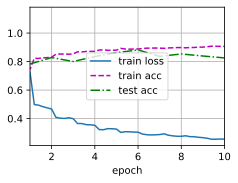

In [3]:
net = nn.Sequential(
    nn.Conv2d(1, 6, kernel_size=5, padding = 2), BatchNorm(6, num_dims=4), nn.Sigmoid(),
    nn.AvgPool2d(kernel_size=2, stride=2),
    nn.Conv2d(6, 16, kernel_size=5), BatchNorm(16, num_dims=4), nn.Sigmoid(),
    nn.AvgPool2d(kernel_size=2, stride=2), nn.Flatten(),
    nn.Linear(16*5*5, 120), BatchNorm(120, num_dims=2), nn.Sigmoid(),
    nn.Linear(120, 84), BatchNorm(84, num_dims=2), nn.Sigmoid(),
    nn.Linear(84, 10))
lr, num_epochs, batch_size = 1.0, 10, 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)
d2l.train_ch6(net, train_iter, test_iter, num_epochs, lr, d2l.try_gpu())

In [5]:
net[1].gamma.reshape((-1,)), net[1].beta.reshape((-1,))

(tensor([1.7410, 0.5284, 2.6295, 2.8697, 3.8776, 3.3927], device='cuda:0',
        grad_fn=<ReshapeAliasBackward0>),
 tensor([-1.7263, -0.8999, -1.5558, -0.7059, -2.4993, -3.1358], device='cuda:0',
        grad_fn=<ReshapeAliasBackward0>))

## 简洁实现

loss 0.448, train acc 0.832, test acc 0.818
31356.4 examples/sec on cuda:0


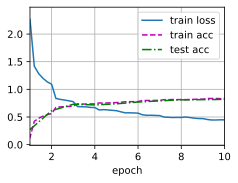

: 

In [ ]:
net = nn.Sequential(
    nn.Conv2d(1, 6, kernel_size=5, padding = 2), nn.BatchNorm2d(6), nn.Sigmoid(),
    nn.AvgPool2d(kernel_size=2, stride=2),
    nn.Conv2d(6, 16, kernel_size=5), nn.BatchNorm2d(16), nn.Sigmoid(),
    nn.AvgPool2d(kernel_size=2, stride=2), nn.Flatten(),
    nn.Linear(16*5*5, 120), nn.BatchNorm1d(120), nn.Sigmoid(),
    nn.Linear(120, 84), nn.BatchNorm1d(84), nn.Sigmoid(),
    nn.Linear(84, 10))
net2 = nn.Sequential(
    nn.Conv2d(1, 6, kernel_size=5,padding = 2), nn.Sigmoid(),
    nn.AvgPool2d(kernel_size=2, stride=2),
    nn.Conv2d(6, 16, kernel_size=5), nn.Sigmoid(),
    nn.AvgPool2d(kernel_size=2, stride=2), nn.Flatten(),
    nn.Linear(16*5*5, 120), nn.Sigmoid(),
    nn.Linear(120, 84), nn.Sigmoid(),
    nn.Linear(84, 10))
d2l.train_ch6(net2, train_iter, test_iter, num_epochs, lr, d2l.try_gpu())

## BN前的偏置
BN 内部的可学习参数 $\boldsymbol{\beta}$ 承担了原本偏置 b 的平移功能,故如果在全连接和卷积后面加了BN层，可以设置`bias = False`，注意只有紧挨着BN层的全连接和卷积可以删掉偏置b

# 其他归一化
## 1. LayerNorm（LN 层归一化）

### 统计维度：**同一个样本内部，全部通道 + 全部空间 $(C,H,W)$**

- 对**每一张图片单独**，把它所有通道所有像素放一起算均值方差
- ❌ **完全不依赖 Batch (N)**，和批次大小无关

### 特点

1. 没有训练 / 推理两套逻辑！不需要维护移动均值方差，训练 eval 行为一致；
2. Transformer、BERT、RNN **标准标配**（序列模型 batch 经常很小、长度可变，BN 无法使用）；
3. CNN 中很少使用；

## 2. InstanceNorm（IN 实例归一化）

### 统计维度：**同一个样本、同一个通道，只在空间维度 $(H,W)$**

每张图、每个通道**独立归一化**。

### 特点

1. 同样不依赖 batch；
2. 效果：抹除单张图像的光照、对比度、色彩风格信息，保留内容结构；
3. ✅ **经典场景：风格迁移、GAN、图像生成**；
4. 分类任务几乎不用。

## 3. GroupNorm（GN 组归一化）

### 统计维度：同一个样本，把通道划分为 G 组，**组内通道 + H,W**

通道 C 分成 G 组，每组内部一起归一化。

### 两个极限等价关系（重点考点）

- $G=1$ → 等价 LayerNorm
- $G=C$ → 等价 InstanceNorm

### 特点

1. 不依赖 batch size；
2. **BN 的替代方案**：检测、分割任务每张 GPU 只能放 2~4 张图（小 batch），BN 统计噪声巨大，改用 GN；
3. ResNet、MaskRCNN 小 batch 训练广泛使用。

| 归一化         | 对哪些维度求均值方差            | 不受谁影响           |
| -------------- | ------------------------------- | -------------------- |
| BatchNorm2d    | N,H,W，按通道 c 分组            | 受 batch 大小 N 影响 |
| InstanceNorm2d | H,W，按「样本 n，通道 c」分组   | 和 batch N 无关      |
| GroupNorm      | H,W，按「样本 n，通道组 g」分组 | 和 batch N 无关      |